Module 1 — State Management Fundamentals in Python

Our objective is to understand five things:
1. What constitutes state in a program?
2. How is state created, accessed, and updated?
3. Mutable vs immutable state — why does it matter?
4. How does state pass between functions or agents?
5. How would you explain these concepts in an interview?


1. State is more than just a variable
Consider a document retrieval workflow:

In [1]:
state = {
    "query": "Sweden contractor leave policy",
    "status": "pending",
    "documents": [],
    "retry_count": 0
}

All four fields represent aspects of the workflow's current state.

Field	    What it represents
query	    Input/context
status	    Execution progress
documents	Intermediate results
retry_count	Recovery information

Key distinction: 
    A variable holds a value. State is the collection of information describing the system's condition at a particular moment.

State can be held in variables, objects, dictionaries, databases, or distributed stores.

2. Worked example 1 - Mutable state 

In [4]:
state = {
    "status": "pending", 
    "documents": []
    }

def retrieve(state):
    state["documents"].append("policy_2026.pdf)")
    state["status"]= "completed"

retrieve(state)
print (state)

{'status': 'completed', 'documents': ['policy_2026.pdf)']}


Python dictionaries and lists are mutable. When passed to a function, the function receives a reference to the same object.

Question: What is the downside of updating shared mutable state directly?
Answer: Other parts of the application can observe unexpected changes. 
This can make debugging, testing, concurrency, and tracking state transitions more difficult.

3. Worked example 2 — Creating a new state

In [6]:
state = {
    "status": "pending",
    "documents": []
}

def retrieve(state):
    return {
        **state,
        "status": "completed",
        "documents": ["Policy_2026.pdf"]
    }

new_state = retrieve(state)

print(state["status"])      # pending
print(new_state["status"])  # completed

pending
completed


Why is this useful?
In a multi-step agent workflow, it becomes easier to reason about explicit transitions:

State S0 (status = pending)
|
retrueve (S0) 
|
State S1 (status = completed)

This is conceptually similar to how a workflow engine coordinates state transitions.
However, returning a new dictionary does not automatically make a system thread-safe or guarantee durable state history.


4. Worked example 3 — Passing state across agent steps

Here is a deliberately small agent-like workflow.

In [8]:
def planner(state):
    return {**state, "plan": "Retrieve policy"}

def researcher(state):
    return {**state, "docs": ["Policy 2026"]}

def summarizer(state):
    return {**state, "answer": f"Found {state['docs'][0]}"}

state = {"query": "Sweden leave policy"}

state = planner(state)
state = researcher(state)
state = summarizer(state)

print(state)
print (state["plan"])
print (state["answer"])


{'query': 'Sweden leave policy', 'plan': 'Retrieve policy', 'docs': ['Policy 2026'], 'answer': 'Found Policy 2026'}
Retrieve policy
Found Policy 2026


There are three interesting points here:

- Every function receives the existing workflow context.
- Each function contributes a new field without discarding existing fields.
- Subsequent functions depend on state produced by previous steps.

This is the foundational idea behind stateful multi-step agent orchestration.

In LangGraph, for example, nodes can return partial state updates that the framework merges according to the state schema and configured reducers.

Exercise: A workflow begins with a document awaiting processing. Write a function called process_document(state) that returns an updated state without modifying the original dictionary.


Refer to the below notebook for the solution:  "track agent state change.ipynb"

### Some important Questions

1. If one agent changes the shared state, will other agents automatically see the change?

Only if they access the same mutable state or receive the updated state through orchestration. Separate processes do not automaticallly share python memory. In a distributed system, state must be explicitly communicated or persisted. 

2. What is the difference between state management and state persistence?
State management controls how information changes during execution. State persistence saves information durably, typicaly in a database or checkpoint store, so it can survice failure or restarts. 

Summary 
State management is how a system maintains, updates, and coordinates information across execution steps. In agentic workflows, each agent reads the relevant context, performs its task, and returns updates that influence subsequent execution. Explicit state transitions improve predictability, debugging, testing, and recovery.

### Module 2 - Asynchronous State and Concurrency 

1. Why is concurrentcy a problem for state management?

Imagine you have two AI agents working simultaneously:
    * Agent A rerieves policy documents. 
    * Agent B retrieves employee information. 
    * Both need to update the same workflow state. 

The challenge isn't simlpy that theu run simultaneously. Its what happens when they both read and modify shared information. 

In [10]:
# Example: Two Agents updating the same counter

import asyncio 

state = {"completed_tasks": 0}

async def agent(name):
    count = state["completed_tasks"]

    await asyncio.sleep(0.1)
    state["completed_tasks"] = count + 1 

async def main(): 
    await asyncio.gather(
        agent("Research"),
        agent("Validation")
    )
    print (state)

await main()

{'completed_tasks': 1}


Expected Result: 
{'completed_tasks': 2}

Two agents completing their tasks, so the count should be two. But the answer is 1. 

Why ? Because, both coroutines read the counter before either updates it.. i.e. Lost Update 

Agent A                                     Agent B 
Read Coutner = 0                            Read Counter = 0 
Await I/O                                   Await I/O
Write Counter = 1                           Write Counter = 1 

So, Final Counter = 1, (xpected=2)
One update is Lost ... 

This is called RACE CONDITION!!!

The result depends on the order in which concurrent operations access shared state.

Important Python detail: In this example, the await allows the coroutine to suspend between reading and writing. The fact that asyncio normally uses one thread does not automatically prevent race conditions.

**Solution A - Use asyncio.Lock**

**Solution B - Isolated agent state and merging**

**Solution A - Use asyncio.Lock**

In [12]:
import asyncio
state = {"completed_tasks": 0}
lock = asyncio.Lock()

async def agent(name):
    async with lock: 
        count = state["completed_tasks"]
        await asyncio.sleep(0.1)
        state["completed_tasks"] = count + 1

async def main():
    await asyncio.gather(
        agent("Research"),
        agent("Validation")
    )
    print (state)

await main()

{'completed_tasks': 2}


This lock ensures only one coroutine at a time can execute the protected critical section

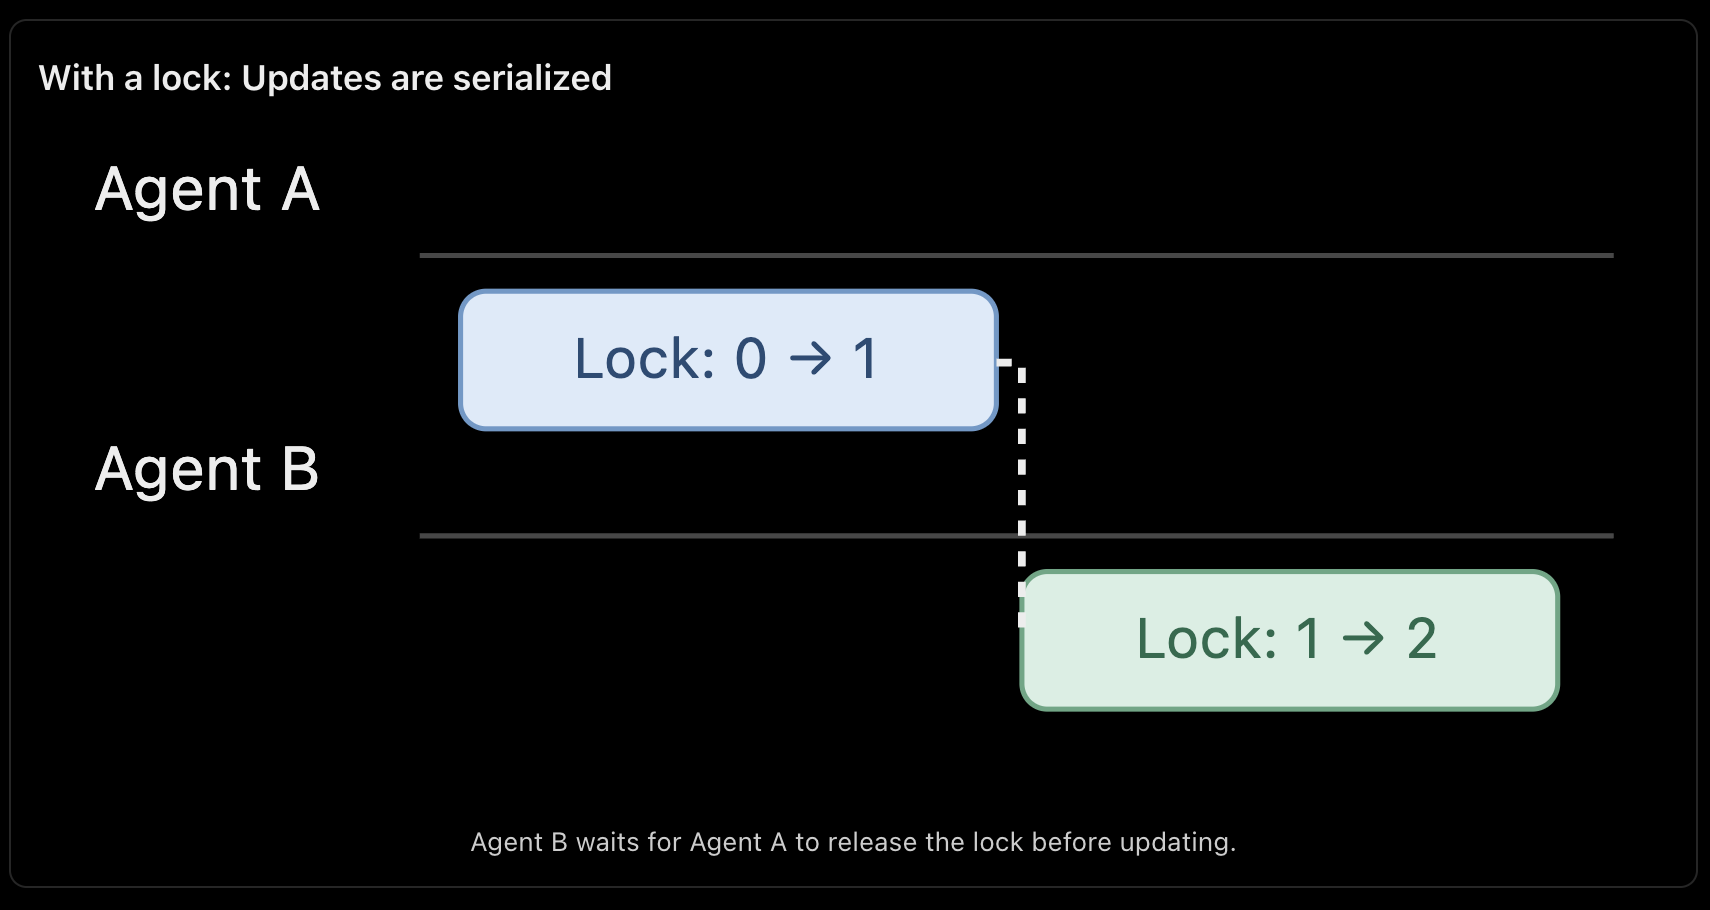

Question: 
Are locks always the best solution ?

No. Locks can reduce concurrency. 

Furthermore, asyncio.Lock only coordinates coroutines sharing that lock within the same event loop. 

In a distributed agent system running across multiple workers or containers, you need stronger coordination mechanisms such as database transactions, optimistic locking, or distributed coordination.

Also, avoid holding a lock during slow network calls when you can safely keep the critical section smaller.

**Solution B - Isolated agent state and merging**
This is particularly relevant to multi-agent workflows.

Instead of letting both agents modify the same dictionary, have them produce independent updates.

In [22]:
import asyncio

async def research_agent():
    await asyncio.sleep(0.1)
    return {"documents": ["Policy_2026.pdf"]}

async def validation_agent():
    await asyncio.sleep(0.1)
    return {"validated": True}

async def main():
    res = await asyncio.gather(
        research_agent(),
        validation_agent()
    )

    state = {"query": "Sweden leave policy"}

    for update in res:
        state.update(update)

    print(state)

await main()


{'query': 'Sweden leave policy', 'documents': ['Policy_2026.pdf'], 'validated': True}


Here, the agents do not modify a shared object directly. They return independent updates, which are merged afterward.

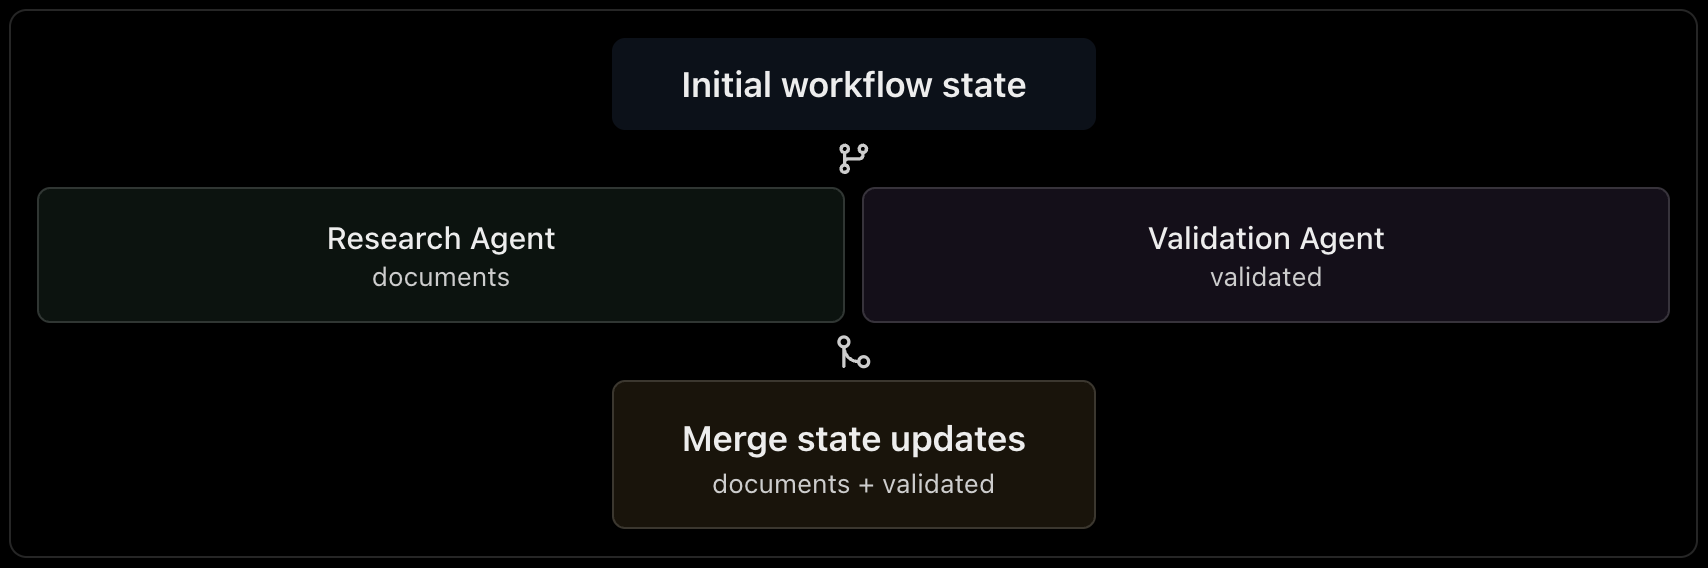

This works cleanly because the agents update different keys.

If two agents update the same key, however, you must define a conflict resolution rule. Simply using dict.update() means the later update wins, which may be incorrect.

In LangGraph, reducers can be used to combine concurrent updates to a shared state field.


In [25]:
# 4. Quick coding exercise — 5 minutes
# Consider this small multi-agent workflow

import asyncio

async def agent_a():
    return {"results": ["Document A"]}

async def agent_b():
    return {"results": ["Document B"]}

async def main():
    results = await asyncio.gather(
        agent_a(), agent_b()
    )

    state = {"results": []}

    # for result in results:
    #     state.update(result)

    for result in results:
        state["results"].extend(result["results"])

    print(state)

await main()


{'results': ['Document A', 'Document B']}


Interview Questions:

Q1. How would you manage state when three agents execute in parallel?

Have each agent produce an independent state update. Merge results through an explicit aggregation step. 
Where agents contribute to the same field, define appropriate merge semantics, such as combining lists, selecting a version, or rejecting conflicting updates.

Q2. Is asyncio.Lock sufficient for multi-agent production infrastructure?

Only when the shared state is accessed by coroutines within the same event loop and all relevant operations use the same lock. Distributed agents require coordination through durable storage, concurrency controls, or other distributed mechanisms.

Q3. How would you prevent duplicate tool executions after a retry?

Use an idempotency key or unique operation identifier, record execution outcomes in durable storage, and ensure retries do not repeat external side effects such as ticket creation or payment processing.

One Statement Summary: 

In parallel agent execution, I prefer isolated state updates with explicit merge semantics over uncontrolled shared mutable state, and I use appropriate concurrency controls when shared updates are unavoidable.
